# 05b · Consensus NMF metaprograms for AT2 cells

Second half of the consensus NMF step (paper Methods: *Non-malignant lung single cell data processing*; Figure 1F). Runs in R 4.3 with Seurat 5 and GeneNMF.

**Input**: `AT2_seurat_object_figs.rds` (File 05a)

**Steps**
1. Split the AT2 cells by sample (`SplitObject`).
2. Run NMF per sample with `multiNMF` (k = 4–9, top 1,000 features).
3. Extract up to 50 metaprograms of at most 50 genes each with `getMetaPrograms` (45 non-empty MPs), and plot their similarity (Figure 1F).
4. Write the metaprograms to GMT files, one with all MPs and one with MPs of ≥ 5 genes (37 MPs, used downstream).

**Output**
- `intermediate_files/lung/metaprograms_gene_sets_healthy_lung_figs.gmt` (all MPs)
- `intermediate_files/lung/metaprograms_gene_sets_healthy_lung_figs_min5.gmt` (MPs with ≥ 5 genes)
- `intermediate_files/lung/geneNMF_programs.RData`, `intermediate_files/lung/geneNMF.metaprograms.RData`
- `figures/metaprograms_plot.pdf`, `metaprograms_plot.svg`

*Note*: the SVG export cell was not run in the saved session, so it shows no execution count.

## Setup

In [1]:
library(GeneNMF)
library(Seurat)
library(ggplot2)

In [2]:
# Paths: edit to match your environment
data_dir <- "intermediate_files/lung"
in_rds <- "AT2_seurat_object_figs.rds"  # output of File 05a

## 1. Load and split by sample

In [3]:
AT2 <- readRDS(file = in_rds)

In [4]:
AT2

An object of class Seurat 
43496 features across 115666 samples within 1 assay 
Active assay: RNA (43496 features, 0 variable features)
 2 layers present: counts, data

In [5]:
seu.list <- SplitObject(AT2, split.by = "sample")

In [6]:
seu.list

$F01641
An object of class Seurat 
43496 features across 334 samples within 1 assay 
Active assay: RNA (43496 features, 0 variable features)
 2 layers present: counts, data

$GSM4906348
An object of class Seurat 
43496 features across 781 samples within 1 assay 
Active assay: RNA (43496 features, 0 variable features)
 2 layers present: counts, data

$NML3_Lin
An object of class Seurat 
43496 features across 182 samples within 1 assay 
Active assay: RNA (43496 features, 0 variable features)
 2 layers present: counts, data

$SC20
An object of class Seurat 
43496 features across 3208 samples within 1 assay 
Active assay: RNA (43496 features, 0 variable features)
 2 layers present: counts, data

$Duong_lungMAP_unpubl_sample_3
An object of class Seurat 
43496 features across 769 samples within 1 assay 
Active assay: RNA (43496 features, 0 variable features)
 2 layers present: counts, data

$`distal 1a`
An object of class Seurat 
43496 features across 482 samples within 1 assay 
Active assay

## 2. NMF per sample and consensus metaprograms

In [7]:
geneNMF.programs <- multiNMF(seu.list, assay="RNA", slot="data", k=4:9, nfeatures = 1000)

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“Feature names cannot have underscores '_', replacing with dashes '-'TRUE”
Warning message:
“Not all features provided are in this Assay object, removing the following feature(s): Y-RNA-295”
Warning message:
“Feature names cannot have underscores '_', replacing with dashes '-'TRUE”
Warning message:
“Not all features provided are in this Assay object, removing the following feature(s): Y-RNA-420”
Warning message:
“Feature names cannot have underscores '_', replacing with dashes '-'TRUE”
Warning message:
“Not all features provided are in this Assay object, removing the following feature(s): Y-RNA-295”
Warning message:
“Feature names cannot have underscores '_', replacing with dashes '-'TRUE”
War

Warning message:
“Feature names cannot have underscores '_', replacing with dashes '-'TRUE”
Warning message:
“Not all features provided are in this Assay object, removing the following feature(s): SNORD3D-ENSG00000281000, F3-ENSG00000117525, ZBED1-ENSG00000214717, SLC25A6-ENSG00000169100, C2-ENSG00000166278, SPATA13-ENSG00000182957, MFSD14CP-ENSG00000196312, POLR2J3-ENSG00000168255, GTPBP6-ENSG00000178605, ELFN2-ENSG00000166897, ASMTL-ENSG00000169093, AKAP17A-ENSG00000197976, MATR3-ENSG00000015479, LINC00869-ENSG00000277147, C9orf72-ENSG00000147894, LTO1-ENSG00000149716, C7-ENSG00000112936, LINC00484-ENSG00000235641, LINC00685-ENSG00000226179, PPP2R3B-ENSG00000167393, MKKS-ENSG00000125863, C3-ENSG00000125730, HERC3-ENSG00000138641, CD99-ENSG00000002586, SVIL-AS1-ENSG00000224597, SFTA3-ENSG00000229415, TRIM16L-ENSG00000108448”
Warning message:
“Feature names cannot have underscores '_', replacing with dashes '-'TRUE”
Warning message:
“Not all features provided are in this Assay object, 

Warning message:
“Feature names cannot have underscores '_', replacing with dashes '-'TRUE”
Warning message:
“Not all features provided are in this Assay object, removing the following feature(s): SLC25A6-ENSG00000169100, CYP2B7P-ENSG00000256612, ALOX12P2-ENSG00000262943, NSUN5P2-ENSG00000106133, SNORD3D-ENSG00000281000, NBPF25P-ENSG00000272150, POLR2J3-ENSG00000168255, CROCCP2-ENSG00000215908, VAMP7-ENSG00000124333, CSF2RA-ENSG00000198223, RRP7BP-ENSG00000182841, LINC03006-ENSG00000272693, DNAJC9-AS1-ENSG00000236756, RAET1E-AS1-ENSG00000223701, GOLGA2P5-ENSG00000238105, PMS2P4-ENSG00000067601, ZNF286B-ENSG00000249459, HERC2P3-ENSG00000180229, TPTEP1-ENSG00000100181, CCT6P3-ENSG00000234585, Y-RNA-ENSG00000202318, GPR84-AS1-ENSG00000258137, Metazoa-SRP-ENSG00000278732, NPEPPSP1-ENSG00000274487, OTOAP1-ENSG00000257838, PDE4DIPP4-ENSG00000275585, TEKT4P2-ENSG00000188681, TRIM16L-ENSG00000108448, ANKRD20A5P-ENSG00000186481, HERC3-ENSG00000138641, LINC00484-ENSG00000235641, LINC02256-ENSG00

In [8]:
geneNMF.metaprograms <- getMetaPrograms(geneNMF.programs,
                                        nMP=50,
                                        max.genes=50)

Dropped 5 empty meta-programs



## 3. Metaprogram similarity (Figure 1F)

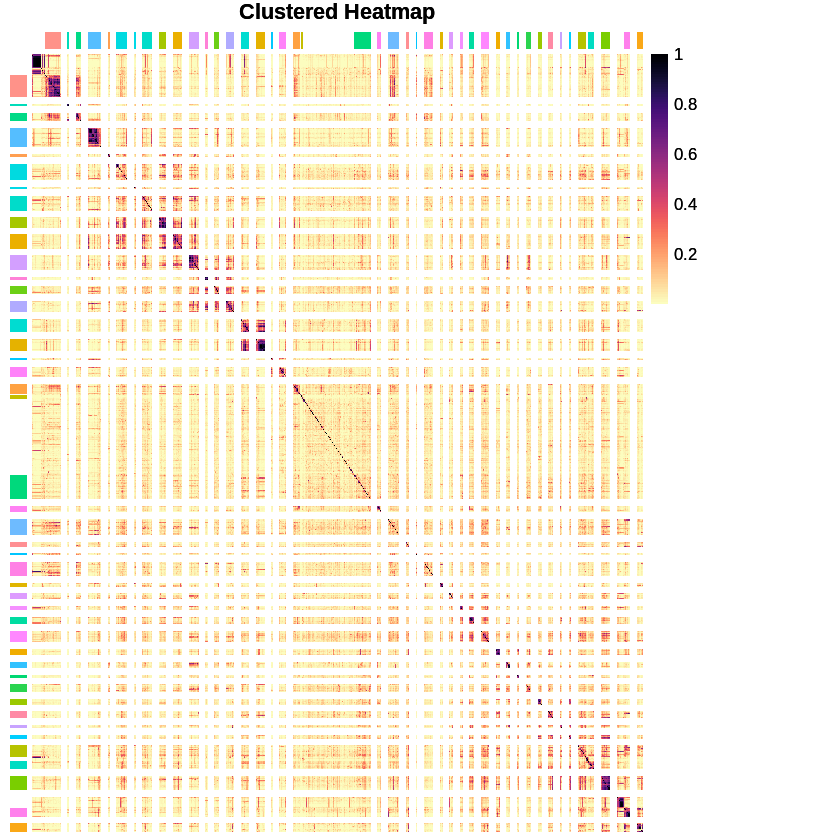

In [9]:
ph <- plotMetaPrograms(geneNMF.metaprograms)
ph

Saving 10 x 7 in image


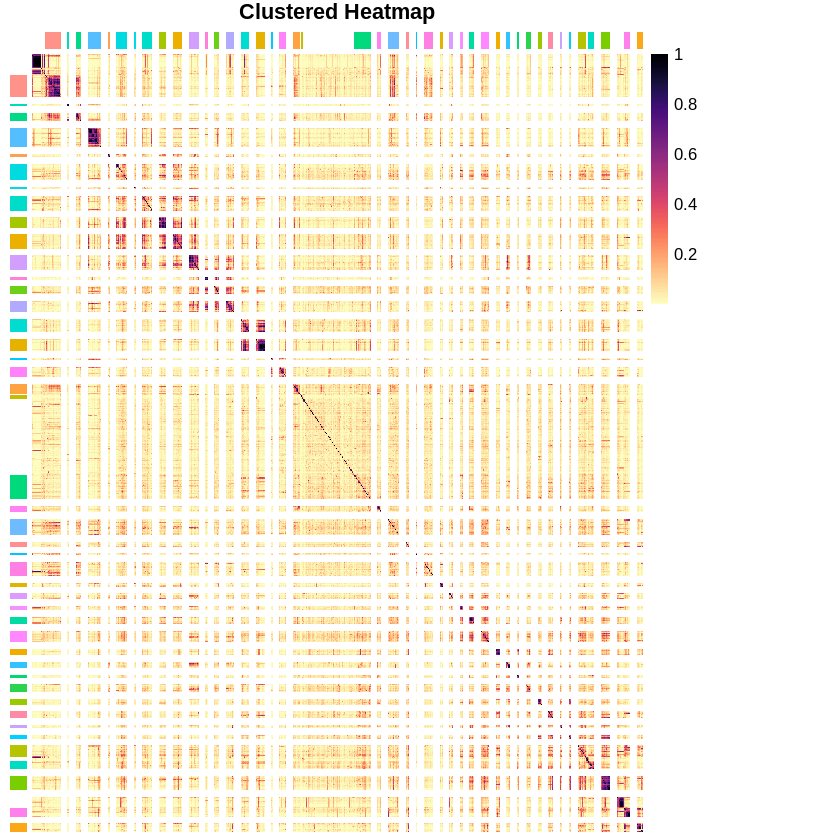

In [10]:
ph <- plotMetaPrograms(geneNMF.metaprograms)
ggsave("figures/metaprograms_plot.pdf", plot = ph, device = "pdf")

In [ ]:
svg("metaprograms_plot.svg", width = 10, height = 7)
ph <- plotMetaPrograms(geneNMF.metaprograms)
dev.off()

In [12]:
geneNMF.metaprograms$metaprograms.metrics

,sampleCoverage,silhouette,meanSimilarity,numberGenes,numberPrograms
,<dbl>,<dbl>,<dbl>,<int>,<chr>
MP1,0.43243243,0.237379968,0.469,17,292
MP2,0.39864865,-0.166908400,0.151,10,230
MP3,0.34459459,-0.161907825,0.222,10,194
MP4,0.29054054,0.553609307,0.711,9,152
MP5,0.29054054,0.322643989,0.549,13,158
MP6,0.27027027,0.081763121,0.431,9,141
MP7,0.27027027,-0.124090475,0.126,2,245
MP8,0.23648649,0.216698882,0.503,16,137
MP9,0.22972973,0.441402804,0.644,5,115


In [13]:
geneNMF.metaprograms$metaprograms.genes

$MP1
 [1] "CAV1"     "AGER"     "CAV2"     "TNNC1"    "ANXA3"    "MYL9"    
 [7] "CEACAM6"  "KRT7"     "CTSE"     "SCEL"     "CLIC5"    "S100A10" 
[13] "ANXA2"    "EMP2"     "C19orf33" "CYP4B1"   "GAS6"    

$MP2
 [1] "MT1E"     "PGC"      "TNNC1"    "FABP5"    "NUPR1"    "C19orf33"
 [7] "RNASE1"   "DBI"      "S100A10"  "MT-ND1"  

$MP3
 [1] "JUN"     "IER2"    "FOS"     "JUNB"    "EGR1"    "GADD45B" "PGC"    
 [8] "DUSP1"   "ZFP36"   "BTG2"   

$MP4
[1] "PGC"     "PIGR"    "WIF1"    "PLA2G1B" "SFTPD"   "HHIP"    "AGR2"   
[8] "CXCL17"  "RNASE1" 

$MP5
 [1] "CXCL2"  "RND1"   "CSF3"   "CXCL1"  "CXCL3"  "NFKBIA" "CXCL8"  "EGR1"  
 [9] "SOCS3"  "ZFP36"  "ICAM1"  "NFKBIZ" "ELF3"  

$MP6
[1] "CXCL1"   "CSF3"    "CXCL3"   "CXCL8"   "CCL20"   "RND1"    "CXCL2"  
[8] "ICAM1"   "TNFAIP3"

$MP7
[1] "LRRK2"   "ZNF385B"

$MP8
 [1] "EGR1"    "FOSB"    "JUN"     "IER2"    "FOS"     "ZFP36"   "JUNB"   
 [8] "KLF6"    "NR4A1"   "GADD45B" "CXCL2"   "RHOB"    "TRIB1"   "ATF3"   
[15] "DUSP1"   "CCN1"   

$MP9
[1] "HP"     "FGG"    "CHI3L1" "DMBT1"  "ORM1"  

$MP10
 [1] "DBI"     "FABP5"   "SLC25A5" "PGC"     "NPM1"    "PLA2G1B" "AGR2"   
 [8] "RPL10A"  "CXCL17"  "RPSA"    "SFTPD"   "UQCR10"  "SELENOP" "S100A14"
[15] "NUPR1"   "AQP3"    "PIGR"    "RNASE1"  "IFITM3"  "FOLR1"   "CTSH"   
[22] "WFDC2"   "UBB"     "CA2"     "RPL13A"  "LDHB"    "MID1IP1" "HSPA8"  
[29] "DYNLL1"  "GAPDH"   "IFITM2"  "MALL"    "ACTG1"   "GKN2"    "S100A11"
[36] "PPIB"    "SCGB3A1" "HHIP"    "JUNB"    "TXN"     "CD74"    "SOD3"   
[43] "S100A10" "NNMT"   

$MP11
 [1] "KLF6"   "ATF3"   "DUSP1"  "EGR1"   "FOSB"   "JUN"    "FOS"    "CXCL2" 
 [9] "HBEGF"  "JUNB"   "IER2"   "ERRFI1" "RHOB"   "ZFP36"  "TRIB1" 

$MP12
 [1] "PGC"     "CHI3L2"  "HHIP"    "CHI3L1"  "CA2"     "PLA2G1B" "HP"     
 [8] "CPB2"    "PIGR"    "DMBT1"   "NNMT"    "CXCL17"  "S100A9"  "TFPI"   
[15] "FABP5"   "CD36"    "MSMO1"   "CTSH"    "LAMP3"   "RASGRF1" "AGR2"   
[22] "WIF1"    "DBI"     "SFTPD"   "FOS"     "NUPR1"   "CD74"    "ABCA3"  

$MP13
[1] "MT2A" "MT1X"

$MP14
 [1] "HHIP"    "PTGFR"   "ETV5"    "PGC"     "CD36"    "WIF1"    "DMBT1"  
 [8] "RASGRF1" "CCDC141" "ETV1"    "ELAPOR2" "TTN"     "ACSS3"   "SFTPD"  
[15] "COLEC12" "ACSL4"   "LRRK2"   "ABCA3"   "MFSD2A"  "TMEM164" "CA2"    

$MP15
[1] "TNFRSF12A" "CAV1"      "TM4SF1"    "S100A10"   "ANXA3"     "ANXA2"    
[7] "KRT7"     

$MP16
 [1] "S100A8" "TYROBP" "SRGN"   "LYZ"    "LGALS1" "LAPTM5" "C1QA"   "VIM"   
 [9] "S100A4" "CYBA"   "TIMP1"  "THBS1" 

$MP17
 [1] "KRT7"      "ANXA3"     "CAV1"      "SCEL"      "STMN1"     "CAV2"     
 [7] "CEACAM6"   "ANXA2"     "TNFRSF12A" "PEG10"     "CTSE"      "TUBB"     
[13] "TM4SF1"    "KRT19"     "TNNC1"     "S100A10"   "SFN"       "KRT8"     
[19] "PDLIM2"    "KRT18"     "TACSTD2"   "ACTG1"    

$MP18
 [1] "DMBT1"   "HHIP"    "FGG"     "HSP90B1" "CHI3L1"  "CXCL2"   "PGC"    
 [8] "HP"      "NAMPT"   "PIGR"    "TFPI"    "NPL"     "ACSL4"   "CHI3L2" 
[15] "ABCA3"   "SFTPD"   "STEAP4"  "IFITM3" 

$MP19
 [1] "CLIC5"     "RBMS3"     "CAV1"      "ENTREP1"   "RANBP17"   "ANXA3"    
 [7] "SCEL"      "GPRC5A"    "TMSB4X"    "CAV2"      "ANOS1"     "ACTB"     
[13] "RNASE1"    "EMP2"      "PAPSS2"    "ICAM1"     "CAMK1D"    "ACTG1"    
[19] "ARHGEF26"  "AGER"      "LAMA5"     "SOX4"      "APBB2"     "SUSD2"    
[25] "RPSA"      "CEACAM6"   "RPL13A"    "GLCCI1"    "AQP4"      "FOLR1"    
[31] "SELENOP"   "CYP4B1"    "ANXA2"     "CLDN18"    "KRT7"      "CD55"     
[37] "SFTPD"     "RAB11FIP1" "PTPRE"     "LMO7"      "DAPK2"     "MAML2"    
[43] "PRDX1"     "MAGI3"     "SCGB3A2"  

$MP20
 [1] "TTN"      "CCDC141"  "LRRK2"    "WIF1"     "PGC"      "HHIP"    
 [7] "ACSS3"    "BMP1"     "PRKD1"    "SCN1A"    "ETV5"     "MT-ND2"  
[13] "ADGRV1"   "ERBB4"    "FMN1"     "SNX25"    "SYNE1"    "ARHGEF38"
[19] "ABCA3"    "ZNF385B"  "NTN4"     "CSF3R"    "FOXP2"    "STEAP4"  
[25] "PTPN13"   "RUFY3"    "SFTPD"    "CA2"      "SNX30"    "TANC2"   
[31] "FREM2"    "CPM"      "CACNA2D2"

$MP21
 [1] "MT-ND5"  "MT-ND6"  "MT-ND4L" 

## 4. Save metaprograms

In [14]:
# Write a named list of gene sets to a GMT file
write_gmt_debug <- function(gene_list, file) {
  # Open the file for writing
  con <- file(file, open = "wt")

  # Ensure the file is closed even if an error occurs
  on.exit(close(con), add = TRUE)

  # Write each gene set to the file
  for (name in names(gene_list)) {
    # Ensure the gene set is not empty
    if (length(gene_list[[name]]) > 0) {
      # Debugging: Print the gene set name and the number of genes
      cat("Writing gene set:", name, "with", length(gene_list[[name]]), "genes\n")

      # Create a line with the gene set name, a description (optional), and the genes
      line <- paste(name, "Description", paste(gene_list[[name]], collapse = "\t"), sep = "\t")
      writeLines(line, con)
    } else {
      warning(paste("Gene set", name, "is empty and will be skipped."))
    }
  }
}

# All metaprograms
write_gmt_debug(geneNMF.metaprograms$metaprograms.genes, file.path(data_dir, "metaprograms_gene_sets_healthy_lung_figs.gmt"))

Writing gene set: MP1 with 17 genes
Writing gene set: MP2 with 10 genes
Writing gene set: MP3 with 10 genes
Writing gene set: MP4 with 9 genes
Writing gene set: MP5 with 13 genes
Writing gene set: MP6 with 9 genes
Writing gene set: MP7 with 2 genes
Writing gene set: MP8 with 16 genes
Writing gene set: MP9 with 5 genes
Writing gene set: MP10 with 44 genes
Writing gene set: MP11 with 15 genes
Writing gene set: MP12 with 28 genes
Writing gene set: MP13 with 2 genes
Writing gene set: MP14 with 21 genes
Writing gene set: MP15 with 7 genes
Writing gene set: MP16 with 12 genes
Writing gene set: MP17 with 22 genes
Writing gene set: MP18 with 18 genes
Writing gene set: MP19 with 45 genes
Writing gene set: MP20 with 33 genes
Writing gene set: MP21 with 11 genes
Writing gene set: MP22 with 2 genes
Writing gene set: MP23 with 9 genes
Writing gene set: MP24 with 4 genes
Writing gene set: MP25 with 10 genes
Writing gene set: MP26 with 4 genes
Writing gene set: MP27 with 19 genes
Writing gene set: MP

In [15]:
save(geneNMF.programs, file = file.path(data_dir, "geneNMF_programs.RData"))
# Note: this line saves geneNMF.programs, not geneNMF.metaprograms, despite the file name.
# The file is not used by any downstream notebook; the metaprograms are passed on through the GMT files.
save(geneNMF.programs, file = file.path(data_dir, "geneNMF.metaprograms.RData"))

In [16]:
# Same writer, keeping only metaprograms with ≥ 5 genes
write_gmt_debug <- function(gene_list, file) {
  # Open the file for writing
  con <- file(file, open = "wt")
  on.exit(close(con), add = TRUE)  # Ensure file closure
  
  # Initialize counters
  total_sets <- length(gene_list)
  written_sets <- 0
  skipped_sets <- 0
  
  cat("Total gene sets to process:", total_sets, "\n")
  
  # Write each gene set to the file
  for (name in names(gene_list)) {
    genes <- gene_list[[name]]
    n_genes <- length(genes)
    
    # Skip if fewer than 5 genes
    if (n_genes < 5) {
      cat("[SKIPPED] Gene set:", name, "has", n_genes, "genes (<5)\n")
      skipped_sets <- skipped_sets + 1
      next
    }
    
    # Write sets with ≥5 genes
    cat("[WRITING] Gene set:", name, "with", n_genes, "genes\n")
    line <- paste(name, "Description", paste(genes, collapse = "\t"), sep = "\t")
    writeLines(line, con)
    written_sets <- written_sets + 1
  }
  
  # Summary report
  cat("\nProcessing complete:\n")
  cat("- Total sets processed:", total_sets, "\n")
  cat("- Sets written (≥5 genes):", written_sets, "\n")
  cat("- Sets skipped (<5 genes):", skipped_sets, "\n")
}

write_gmt_debug(
  geneNMF.metaprograms$metaprograms.genes, 
  file.path(data_dir, "metaprograms_gene_sets_healthy_lung_figs_min5.gmt")
)

Total gene sets to process: 45 
[WRITING] Gene set: MP1 with 17 genes
[WRITING] Gene set: MP2 with 10 genes
[WRITING] Gene set: MP3 with 10 genes
[WRITING] Gene set: MP4 with 9 genes
[WRITING] Gene set: MP5 with 13 genes
[WRITING] Gene set: MP6 with 9 genes
[SKIPPED] Gene set: MP7 has 2 genes (<5)
[WRITING] Gene set: MP8 with 16 genes
[WRITING] Gene set: MP9 with 5 genes
[WRITING] Gene set: MP10 with 44 genes
[WRITING] Gene set: MP11 with 15 genes
[WRITING] Gene set: MP12 with 28 genes
[SKIPPED] Gene set: MP13 has 2 genes (<5)
[WRITING] Gene set: MP14 with 21 genes
[WRITING] Gene set: MP15 with 7 genes
[WRITING] Gene set: MP16 with 12 genes
[WRITING] Gene set: MP17 with 22 genes
[WRITING] Gene set: MP18 with 18 genes
[WRITING] Gene set: MP19 with 45 genes
[WRITING] Gene set: MP20 with 33 genes
[WRITING] Gene set: MP21 with 11 genes
[SKIPPED] Gene set: MP22 has 2 genes (<5)
[WRITING] Gene set: MP23 with 9 genes
[SKIPPED] Gene set: MP24 has 4 genes (<5)
[WRITING] Gene set: MP25 with 10 g